<a href="https://colab.research.google.com/github/Arthxzs/Analise_Eleitoral_2026/blob/main/An%C3%A1lise_vota%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Montagem do drive para acessar os arquivos

In [49]:
from google.colab import drive
import os
import numpy as np
import matplotlib.pyplot as plt

drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive/Colab Notebooks/Votacao/data")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Montagem dos dois DF

In [3]:
import pandas as pd

usecols1 = ["NR_TURNO", "SG_UF", "SG_UE", "NM_UE", "NM_MUNICIPIO", "CD_MUNICIPIO", "QT_APTOS", "QT_COMPARECIMENTO", "QT_VOTOS_BRANCOS", "DS_CARGO", "QT_ABSTENCOES", "QT_TOTAL_VOTOS_VALIDOS", "QT_TOTAL_VOTOS_NULOS"] # Selecionando colunas relevantes para a análise
df1 = pd.read_csv("detalhe_votacao_munzona_2026_BRASIL.csv", encoding="ISO-8859-1", sep=";", usecols=usecols1) #Detalhes da votação

usecols2 = ["NM_TIPO_ELEICAO", "SG_UF", "SG_UE", "NM_UE", "CD_MUNICIPIO", "NR_TURNO", "DS_ELEICAO", "NM_MUNICIPIO", "DS_CARGO", "QT_VOTOS_NOMINAIS", "NR_CANDIDATO", "NM_CANDIDATO", "NM_PARTIDO", "QT_VOTOS_NOMINAIS_VALIDOS"]
df2 = pd.read_csv("votacao_candidato_munzona_2026_BRASIL.csv", encoding="ISO-8859-1", sep=";", usecols=usecols2) # Números de votação dos candidatos



Números da eleição

In [4]:
numeros_pres = (df1["DS_CARGO"] == "Presidente") #& (df1["NR_TURNO"] == 2) # & (df1["SG_UF"] == "ZZ")

numeros_pres = df1[numeros_pres].groupby(["NR_TURNO", "DS_CARGO"])[["QT_APTOS", "QT_COMPARECIMENTO", "QT_ABSTENCOES", "QT_TOTAL_VOTOS_NULOS", "QT_VOTOS_BRANCOS", "QT_TOTAL_VOTOS_VALIDOS"]].sum(numeric_only=True).sort_values("QT_TOTAL_VOTOS_VALIDOS", ascending=True)
numeros_pres = numeros_pres.rename(columns={"QT_APTOS": "Eleitores aptos", "QT_COMPARECIMENTO": "Comparecimento", "QT_ABSTENCOES": "Abstenções", "QT_TOTAL_VOTOS_NULOS": "Votos nulos", "QT_VOTOS_BRANCOS": "Votos brancos", "QT_TOTAL_VOTOS_VALIDOS": "Votos nominais"})
numeros_pres = numeros_pres.rename_axis(index={"NR_TURNO": "Turno", "DS_CARGO": "Cargo"})
#numeros_t1 = numeros_t1.reset_index()

display(numeros_pres)

,,Eleitores aptos,Comparecimento,Abstenções,Votos nulos,Votos brancos,Votos nominais
Turno,Cargo,,,,,,
1,Presidente,158745502,125275835,33469244,3674249,2300798,119300788
2,Presidente,158745502,128236074,30509005,2723305,1430496,124082273


Relação de porcentagem entre os números

In [5]:
numeros_pres["% Comparecimento"] = round(((numeros_pres["Comparecimento"] / numeros_pres["Eleitores aptos"]) * 100), 2)
numeros_pres["% Abstenções"] = round(((numeros_pres["Abstenções"] / numeros_pres["Eleitores aptos"]) * 100), 2)
numeros_pres["% Votos em branco"] = round(((numeros_pres["Votos brancos"] / numeros_pres["Comparecimento"]) * 100), 2)
numeros_pres["% Votos nulo"] = round(((numeros_pres["Votos nulos"] / numeros_pres["Comparecimento"]) * 100), 2)
numeros_pres["% Votos nominais"] = round((numeros_pres["Votos nominais"] / (numeros_pres["Comparecimento"]) * 100), 2)

display(numeros_pres["Eleitores aptos"], numeros_pres["% Abstenções"], numeros_pres["% Votos em branco"], numeros_pres["% Votos nulo"], numeros_pres["% Votos nominais"])

,,Eleitores aptos
Turno,Cargo,
1,Presidente,158745502
2,Presidente,158745502


,,% Abstenções
Turno,Cargo,
1,Presidente,21.08
2,Presidente,19.22


,,% Votos em branco
Turno,Cargo,
1,Presidente,1.84
2,Presidente,1.12


,,% Votos nulo
Turno,Cargo,
1,Presidente,2.93
2,Presidente,2.12


,,% Votos nominais
Turno,Cargo,
1,Presidente,95.23
2,Presidente,96.76


Números de votação primeiro e segundo turno para os candidatos

In [6]:
def votacao_candidatos(turno):
  filtro = (df2["NR_TURNO"] == turno) & (df2["DS_CARGO"] == "Presidente")
  votacao_pres = df2[filtro].groupby(["NR_TURNO", "DS_CARGO", "NR_CANDIDATO", "NM_CANDIDATO"])[["QT_VOTOS_NOMINAIS_VALIDOS"]].sum().sort_values("QT_VOTOS_NOMINAIS_VALIDOS", ascending= False)
  votacao_pres = votacao_pres.rename(columns={"QT_VOTOS_NOMINAIS_VALIDOS": "Votos nominais válidos"})
  votacao_pres = votacao_pres.rename_axis(index={"NR_TURNO": "Turno", "DS_CARGO": "Cargo", "NR_CANDIDATO": "Número", "NM_CANDIDATO": "Candidato"})
  votacao_pres["% dos válidos"] = round((votacao_pres["Votos nominais válidos"] / votacao_pres["Votos nominais válidos"].sum() * 100), 2)
  return votacao_pres

votacao_t1 = votacao_candidatos(1)
votacao_t2 = votacao_candidatos(2)

display(votacao_t1)
display(votacao_t2)

Votos nominais válidos  \
Turno Cargo      Número Candidato                                                   
1     Presidente 22     FLAVIO NANTES BOLSONARO                          56104503   
                 13     LUIZ INÁCIO LULA DA SILVA                        53879538   
                 70     AUGUSTO JORGE CURY                                3448569   
                 14     RENAN ANTONIO FERREIRA DOS SANTOS                 2675887   
                 55     RONALDO RAMOS CAIADO                              2605148   
                 30     ROMEU ZEMA NETO                                    326488   
                 80     SAMARA MARTINS DA SILVA FEITOSA                    122911   
                 16     HERTZ DA CONCEICAO DIAS                             43103   
                 27     CLARIANA ZACARKIM BARAO                             40043   
                 21     EDMILSON SILVA COSTA                                22693   
                 35     WILSON GRASSI JUNIOR                                16881   
                 29     RUI COSTA PIMENTA                                   15024   

                                                           % dos válidos  
Turno Cargo      Número Candidato                                         
1     Presidente 22     FLAVIO NANTES BOLSONARO                    47.03  
                 13     LUIZ INÁCIO LULA DA SILVA                  45.16  
                 70     AUGUSTO JORGE CURY                          2.89  
                 14     RENAN ANTONIO FERREIRA DOS SANTOS           2.24  
                 55     RONALDO RAMOS CAIADO                        2.18  
                 30     ROMEU ZEMA NETO                             0.27  
                 80     SAMARA MARTINS DA SILVA FEITOSA             0.10  
                 16     HERTZ DA CONCEICAO DIAS                     0.04  
                 27     CLARIANA ZACARKIM BARAO                     0.03  
                 21     EDMILSON SILVA COSTA                        0.02  
                 35     WILSON GRASSI JUNIOR                        0.01  
                 29     RUI COSTA PIMENTA                           0.01

Votos nominais válidos  \
Turno Cargo      Número Candidato                                           
2     Presidente 13     LUIZ INÁCIO LULA DA SILVA                64256232   
                 22     FLAVIO NANTES BOLSONARO                  59826041   

                                                   % dos válidos  
Turno Cargo      Número Candidato                                 
2     Presidente 13     LUIZ INÁCIO LULA DA SILVA          51.79  
                 22     FLAVIO NANTES BOLSONARO            48.21

Diferença entre primeiro e segundo turno para os candidatos



In [8]:
# Os finalistas são os candidatos do 2º turno
finalistas = votacao_t2.index.get_level_values("Número").tolist()

cand_t1 = votacao_t1.reset_index().set_index("Número").loc[finalistas]
cand_t2 = votacao_t2.reset_index().set_index("Número").loc[finalistas]

ganho_finalistas = pd.DataFrame({"Candidato": cand_t2["Candidato"], "Votos 1º turno": cand_t1["Votos nominais válidos"], "Votos 2º turno": cand_t2["Votos nominais válidos"]})
ganho_finalistas["Diferença"] = ganho_finalistas["Votos 2º turno"] - ganho_finalistas["Votos 1º turno"]
ganho_finalistas["Aumentou?"] = ganho_finalistas["Diferença"] > 0

display(ganho_finalistas)

,Candidato,Votos 1º turno,Votos 2º turno,Diferença,Aumentou?
Número,,,,,
13,LUIZ INÁCIO LULA DA SILVA,53879538,64256232,10376694,True
22,FLAVIO NANTES BOLSONARO,56104503,59826041,3721538,True


Diferença do primeiro pro segundo turno

,Candidato,Votos 1º turno,Votos 2º turno,Diferença,Aumentou?
Número,,,,,
13,LUIZ INÁCIO LULA DA SILVA,53879538,64256232,10376694,True
22,FLAVIO NANTES BOLSONARO,56104503,59826041,3721538,True


Voto municipal 2 turnos

Número de municípios

In [39]:
nr_municipios_br = 5569 # Tirado do site do IBGE: https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/15774-malhas.html?=&t=sobre

mun_br = df2["SG_UF"] != "ZZ"
nr_municipio = df2[mun_br][["CD_MUNICIPIO"]].nunique().to_frame()
nr_municipio = nr_municipio.rename(columns={0: "N municípios"})

display(nr_municipio)

#Brasília e o DF não são considerados municípios propriamente ditos pelo IBGE
#Porém são considerados nessa contagem do TSE, por isso a diferença

,N municípios
CD_MUNICIPIO,5571


In [68]:
regioes = {"AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
           "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
           "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
           "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
           "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
           "PR": "Sul", "RS": "Sul", "SC": "Sul", "ZZ": "Exterior"}

estados_br = (df2["SG_UF"] != "ZZ") & (df2["DS_CARGO"] == "Presidente")

votacao_estados = df2[estados_br].groupby(["SG_UF"])[["QT_VOTOS_NOMINAIS_VALIDOS"]].sum(numeric_only=True).sort_values("QT_VOTOS_NOMINAIS_VALIDOS", ascending=False)

display(votacao_estados)

,QT_VOTOS_NOMINAIS_VALIDOS
SG_UF,
SP,51141400
MG,24569120
RJ,19104126
BA,17654310
PR,13443191
RS,13121976
PE,11551084
CE,11473416
PA,9753561


Regioes (Daqui pra baixo é IA, será modificado ainda pra ser feito a mão, mas preguiça por enquanto)

In [53]:
# Decomposição do ganho dos finalistas entre os turnos:
# ganho = votos dos eliminados no 1º turno + queda de abstenções + queda de nulos + queda de brancos (+ resíduo)
total_t1 = numeros_pres.loc[(1, "Presidente")]
total_t2 = numeros_pres.loc[(2, "Presidente")]

eliminados_t1 = votacao_t1["Votos nominais válidos"].sum() - cand_t1["Votos nominais válidos"].sum()
ganho_total = ganho_finalistas["Diferença"].sum()

composicao_ganho = pd.DataFrame({"Votos": [eliminados_t1,
                                           total_t1["Abstenções"] - total_t2["Abstenções"],
                                           total_t1["Votos nulos"] - total_t2["Votos nulos"],
                                           total_t1["Votos brancos"] - total_t2["Votos brancos"]]},
                                index=["Votos dos candidatos eliminados no 1º turno", "Queda de abstenções", "Queda de votos nulos", "Queda de votos brancos"])
composicao_ganho.loc["Resíduo (diferença não explicada pelos dados)"] = ganho_total - composicao_ganho["Votos"].sum()
composicao_ganho.loc["Ganho total dos finalistas"] = ganho_total

display(composicao_ganho)

,Votos
Votos dos candidatos eliminados no 1º turno,9316747.0
Queda de abstenções,2960239.0
Queda de votos nulos,950944.0
Queda de votos brancos,870302.0
Resíduo (diferença não explicada pelos dados),0.0
Ganho total dos finalistas,14098232.0


In [40]:
# Chave do município: SG_UF + CD_MUNICIPIO (o nome do município se repete entre UFs)
filtro_b = (df2["DS_CARGO"] == "Presidente") & (df2["NR_CANDIDATO"].isin(finalistas))

tabela_b = df2[filtro_b].groupby(["SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO", "NR_TURNO", "NR_CANDIDATO"])[["QT_VOTOS_NOMINAIS_VALIDOS"]].sum()
tabela_b = tabela_b.unstack(["NR_TURNO", "NR_CANDIDATO"], fill_value=0)
tabela_b.columns = [f"T{turno}_{cand}" for _, turno, cand in tabela_b.columns]
tabela_b = tabela_b.reset_index()

# Regra do vencedor (13 ou 22; 0 = empate exato), escrita uma vez e usada em município, UF e região
def definir_vencedor(df, col_13, col_22):
    return np.select([df[col_13] > df[col_22], df[col_22] > df[col_13]], [13, 22], default=0)

tabela_b["Vencedor_T1"] = definir_vencedor(tabela_b, "T1_13", "T1_22")
tabela_b["Vencedor_T2"] = definir_vencedor(tabela_b, "T2_13", "T2_22")
tabela_b["Margem_T1"] = tabela_b["T1_13"] - tabela_b["T1_22"]
tabela_b["Margem_T2"] = tabela_b["T2_13"] - tabela_b["T2_22"]

colunas_votos = ["T1_13", "T1_22", "T2_13", "T2_22"]

display(tabela_b.head())

# Conferências: as somas devem fechar com os totais por candidato e turno
display(tabela_b[colunas_votos].sum(), len(tabela_b), df2[df2["DS_CARGO"] == "Presidente"]["CD_MUNICIPIO"].nunique())

,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,T1_13,T1_22,T2_13,T2_22,Vencedor_T1,Vencedor_T2,Margem_T1,Margem_T2
0,AC,1007,BUJARI,2394,5531,2454,5034,22,22,-3137,-2580
1,AC,1015,CAPIXABA,1732,4227,1663,3825,22,22,-2495,-2162
2,AC,1023,PORTO ACRE,2658,7926,2752,7534,22,22,-5268,-4782
3,AC,1031,SANTA ROSA DO PURUS,1384,1258,1476,1123,13,13,126,353
4,AC,1040,MARECHAL THAUMATURGO,3365,5369,2706,4017,22,22,-2004,-1311


,0
T1_13,53879538
T1_22,56104503
T2_13,64256232
T2_22,59826041


5757

5757

In [44]:
regioes = {"AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
           "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
           "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
           "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
           "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
           "PR": "Sul", "RS": "Sul", "SC": "Sul", "ZZ": "Exterior"}

# Criando mun_br como cópia de tabela_b para que possua SG_UF e as colunas de Vencedor
mun_br = tabela_b.copy()

tabela_b["Regiao"] = tabela_b["SG_UF"].map(regioes)
mun_br["Regiao"] = mun_br["SG_UF"].map(regioes)

votos_uf = tabela_b.groupby("SG_UF")[colunas_votos].sum()
votos_regiao = tabela_b.groupby("Regiao")[colunas_votos].sum()

for tabela in (votos_uf, votos_regiao):
    tabela["Vencedor_T1"] = definir_vencedor(tabela, "T1_13", "T1_22")
    tabela["Vencedor_T2"] = definir_vencedor(tabela, "T2_13", "T2_22")

# Conferência: nenhuma UF pode ficar sem região
display(tabela_b["Regiao"].isna().sum(), votos_regiao, votos_uf)

np.int64(0)

,T1_13,T1_22,T2_13,T2_22,Vencedor_T1,Vencedor_T2
Regiao,,,,,,
Centro-Oeste,2963043,5133436,3733919,5603867,22,22
Exterior,157387,143900,200154,171497,13,13
Nordeste,21494584,10398973,24450432,10796736,13,13
Norte,4550602,5009437,5024626,5023547,22,13
Sudeste,19237398,24899609,24037731,26844501,22,22
Sul,5476524,10519148,6809370,11385893,22,22


,T1_13,T1_22,T2_13,T2_22,Vencedor_T1,Vencedor_T2
SG_UF,,,,,,
AC,134770,302807,144513,287715,22,22
AL,995459,735718,1152621,744140,13,13
AM,1046996,976764,1145783,975245,13,13
AP,212503,212278,222968,198674,13,13
BA,5664771,2442585,6485258,2608761,13,13
CE,3555263,1756850,4036124,1819478,13,13
DF,675627,909616,825224,979542,22,22
ES,850028,1233194,1001965,1294504,22,22
GO,1188880,2051888,1585555,2345334,22,22


In [45]:
 # Definição: inversão = vencedor diferente nos dois turnos, sem empate em nenhum deles
filtro_inv = (mun_br["Vencedor_T1"] != mun_br["Vencedor_T2"]) & (mun_br["Vencedor_T1"] != 0) & (mun_br["Vencedor_T2"] != 0)
inversoes_mun = mun_br[filtro_inv]

resumo_inversoes_mun = pd.Series({"Total de municípios que inverteram": len(inversoes_mun),
                                  "Inverteram a favor do 13": (inversoes_mun["Vencedor_T2"] == 13).sum(),
                                  "Inverteram a favor do 22": (inversoes_mun["Vencedor_T2"] == 22).sum(),
                                  "Municípios com empate no 1º turno": (mun_br["Vencedor_T1"] == 0).sum(),
                                  "Municípios com empate no 2º turno": (mun_br["Vencedor_T2"] == 0).sum()})

inversoes_uf = votos_uf[votos_uf["Vencedor_T1"] != votos_uf["Vencedor_T2"]]
inversoes_regiao = votos_regiao[votos_regiao["Vencedor_T1"] != votos_regiao["Vencedor_T2"]]

display(resumo_inversoes_mun, inversoes_uf, inversoes_regiao)

,0
Total de municípios que inverteram,222
Inverteram a favor do 13,218
Inverteram a favor do 22,4
Municípios com empate no 1º turno,44
Municípios com empate no 2º turno,43


,T1_13,T1_22,T2_13,T2_22,Vencedor_T1,Vencedor_T2
SG_UF,,,,,,
MG,5188936,5777548,6351099,6241786,22,13


,T1_13,T1_22,T2_13,T2_22,Vencedor_T1,Vencedor_T2
Regiao,,,,,,
Norte,4550602,5009437,5024626,5023547,22,13


In [46]:
# Cidades que não inverteram (e sem empate)
nao_inverteram = mun_br[(mun_br["Vencedor_T1"] == mun_br["Vencedor_T2"]) & (mun_br["Vencedor_T1"] != 0)].copy()
colunas_top = ["SG_UF", "NM_MUNICIPIO", "Vencedor_T1", "Margem_T1", "Margem_T2"]

# Interpretação 1: maior variação da margem (13 - 22) entre os turnos
nao_inverteram["Variação da margem"] = nao_inverteram["Margem_T2"] - nao_inverteram["Margem_T1"]
nao_inverteram["Variação absoluta"] = nao_inverteram["Variação da margem"].abs()
top20_variacao = nao_inverteram.nlargest(20, "Variação absoluta")[colunas_top + ["Variação da margem"]]

# Interpretação 2: maior diferença de votos entre os 2 candidatos no 2º turno
nao_inverteram["Margem absoluta T2"] = nao_inverteram["Margem_T2"].abs()
top20_margem_t2 = nao_inverteram.nlargest(20, "Margem absoluta T2")[colunas_top]

display(top20_variacao, top20_margem_t2)

,SG_UF,NM_MUNICIPIO,Vencedor_T1,Margem_T1,Margem_T2,Variação da margem
5362,SP,SÃO PAULO,13,291602,766431,474829
527,BA,SALVADOR,13,553170,732320,179150
688,CE,FORTALEZA,13,210751,312648,101897
803,DF,BRASÍLIA,22,-233989,-154318,79671
1468,MG,BELO HORIZONTE,22,-98923,-24183,74740
2918,PE,RECIFE,13,166280,233027,66747
154,AM,MANAUS,22,-202837,-137474,65363
2446,PA,BELÉM,13,35193,85434,50241
5047,SP,GUARULHOS,22,-64280,-16201,48079
4246,RS,PORTO ALEGRE,13,52113,95329,43216


,SG_UF,NM_MUNICIPIO,Vencedor_T1,Margem_T1,Margem_T2
5362,SP,SÃO PAULO,13,291602,766431
527,BA,SALVADOR,13,553170,732320
688,CE,FORTALEZA,13,210751,312648
3330,PR,CURITIBA,22,-296622,-277152
2918,PE,RECIFE,13,166280,233027
1006,GO,GOIÂNIA,22,-209389,-203524
3141,PI,TERESINA,13,143840,178352
4596,SC,JOINVILLE,22,-173390,-172564
803,DF,BRASÍLIA,22,-233989,-154318
1319,MA,SÃO LUÍS,13,108345,149874


In [48]:
pct_cidades_22 = pd.DataFrame({"% cidades do 22 - 1º turno": (mun_br["Vencedor_T1"] == 22).groupby(mun_br["SG_UF"]).mean() * 100,
                               "% cidades do 22 - 2º turno": (mun_br["Vencedor_T2"] == 22).groupby(mun_br["SG_UF"]).mean() * 100})
pct_cidades_22 = pct_cidades_22.sort_values("% cidades do 22 - 1º turno", ascending=False)

display(pct_cidades_22.round(2))

,% cidades do 22 - 1º turno,% cidades do 22 - 2º turno
SG_UF,,
DF,100.00,100.00
RO,100.00,100.00
SC,98.31,97.97
SP,93.80,88.84
MT,93.66,92.25
RR,93.33,93.33
MS,92.41,87.34
RS,91.55,87.73
RJ,90.22,80.43


Gráficos

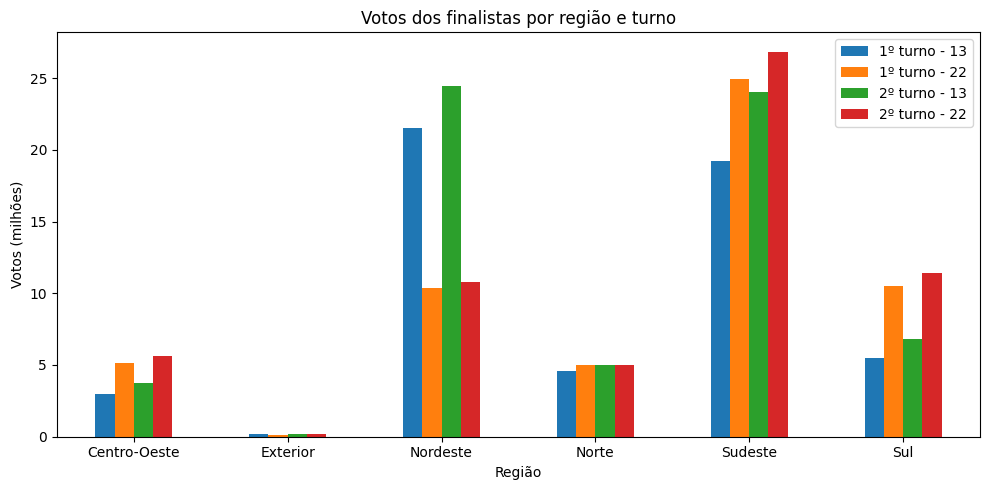

In [50]:
# Gráfico 1: votos dos 2 candidatos por região e turno
votos_regiao_mi = votos_regiao[colunas_votos] / 1_000_000
votos_regiao_mi.columns = ["1º turno - 13", "1º turno - 22", "2º turno - 13", "2º turno - 22"]
votos_regiao_mi.plot(kind="bar", figsize=(10, 5))
plt.title("Votos dos finalistas por região e turno")
plt.ylabel("Votos (milhões)")
plt.xlabel("Região")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

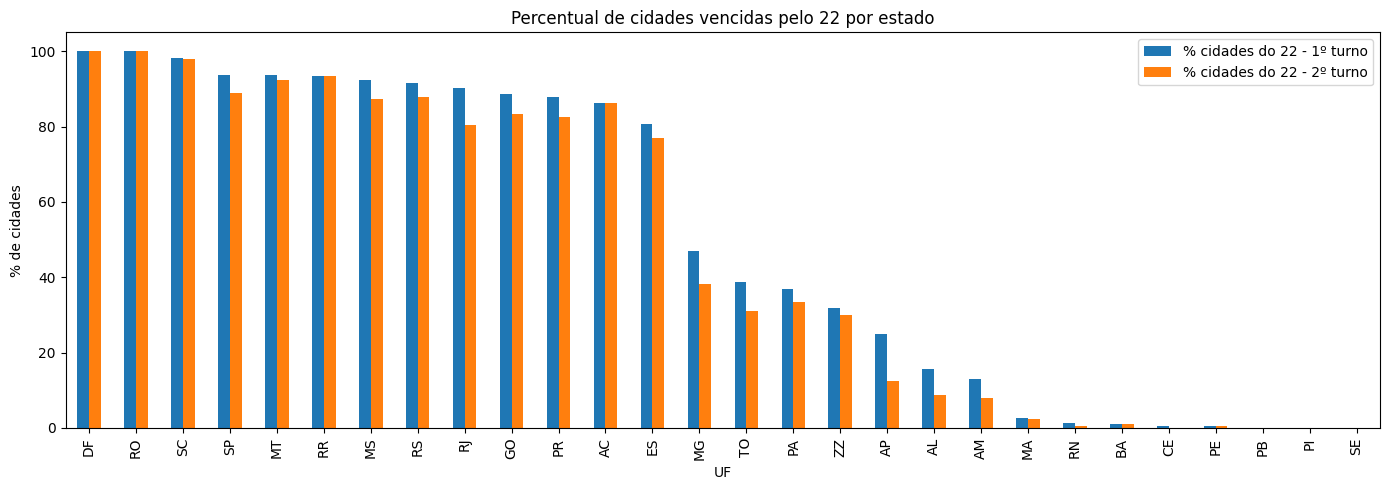

In [51]:
# Gráfico 2: percentual de cidades vencidas pelo 22, por estado, em cada turno
pct_cidades_22.plot(kind="bar", figsize=(14, 5))
plt.title("Percentual de cidades vencidas pelo 22 por estado")
plt.ylabel("% de cidades")
plt.xlabel("UF")
plt.tight_layout()
plt.show()

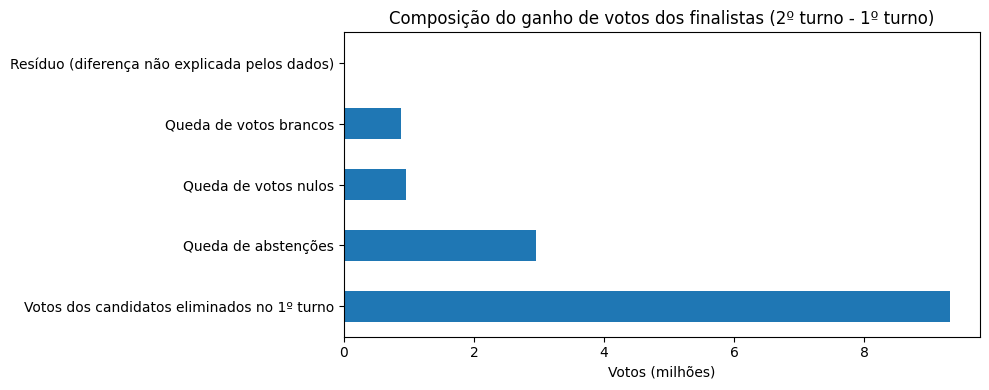

In [54]:
# Gráfico 3: de onde veio o ganho de votos dos finalistas entre os turnos
(composicao_ganho.drop("Ganho total dos finalistas")["Votos"] / 1_000_000).plot(kind="barh", figsize=(10, 4))
plt.title("Composição do ganho de votos dos finalistas (2º turno - 1º turno)")
plt.xlabel("Votos (milhões)")
plt.tight_layout()
plt.show()